# Time Series Forecasting

Time series data is ordered in time, so random train/test splits leak information from the future
into the past. This notebook builds a correct forecasting workflow:

- explore trend, seasonality, and noise,
- test for stationarity,
- create lag features,
- validate with a chronological split and walk-forward validation,
- forecast with a moving average, linear regression on lags, and ARIMA.

## Learning objectives

1. Explain why time-ordered validation differs from random cross-validation.
2. Decompose a series into trend, seasonality, and residual.
3. Test stationarity with the augmented Dickey-Fuller test.
4. Build lag features and forecast with regression.
5. Fit and evaluate an ARIMA model.

## 1. Concepts

### Components of a time series

- **Trend**: long-term direction.
- **Seasonality**: repeating pattern with a fixed period (monthly, weekly, daily).
- **Cyclicality**: longer, irregular fluctuations.
- **Noise**: unexplained variation.

### Stationarity

A stationary series has constant mean, variance, and autocorrelation over time. Many classical models
(ARIMA) assume or transform toward stationarity. The augmented Dickey-Fuller (ADF) test has:

- null hypothesis: the series has a unit root (non-stationary),
- alternative: the series is stationary.

A small p-value suggests rejecting the null and treating the series as stationary.

### Validation

- Use a **chronological split**: train on earlier data, test on later data.
- Use **walk-forward validation**: repeatedly train on the past and predict the next block.
- Never use `train_test_split(shuffle=True)` on time series.
- `TimeSeriesSplit` produces expanding training windows.

### ARIMA(p, d, q)

- `p`: autoregressive terms (past values).
- `d`: differencing order to remove trend.
- `q`: moving-average terms (past forecast errors).

## 2. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

## 3. Create a synthetic monthly series

The series combines a linear trend, a 12-month seasonal pattern, and random noise. A synthetic
series lets us check whether the methods recover the structure we built in.

In [2]:
n_months = 144
time = np.arange(n_months)
dates = pd.date_range(start="2015-01-01", periods=n_months, freq="MS")

trend = 0.8 * time
seasonality = 6 * np.sin(2 * np.pi * time / 12)
noise = np.random.default_rng(RANDOM_STATE).normal(0, 2.0, n_months)
values = 50 + trend + seasonality + noise

series = pd.Series(values, index=dates, name="sales")
series.head()

2015-01-01    50.609434
2015-02-01    51.720032
2015-03-01    58.297055
2015-04-01    60.281129
2015-05-01    54.494082
Freq: MS, Name: sales, dtype: float64

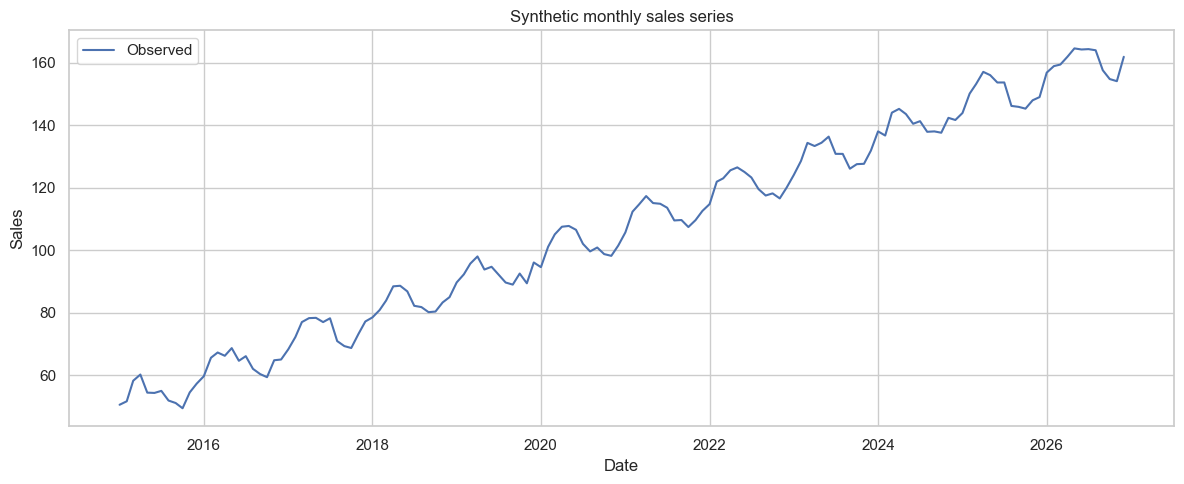

In [3]:
plt.figure(figsize=(12, 5))
plt.plot(series.index, series.values, label="Observed")
plt.title("Synthetic monthly sales series")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Decomposition

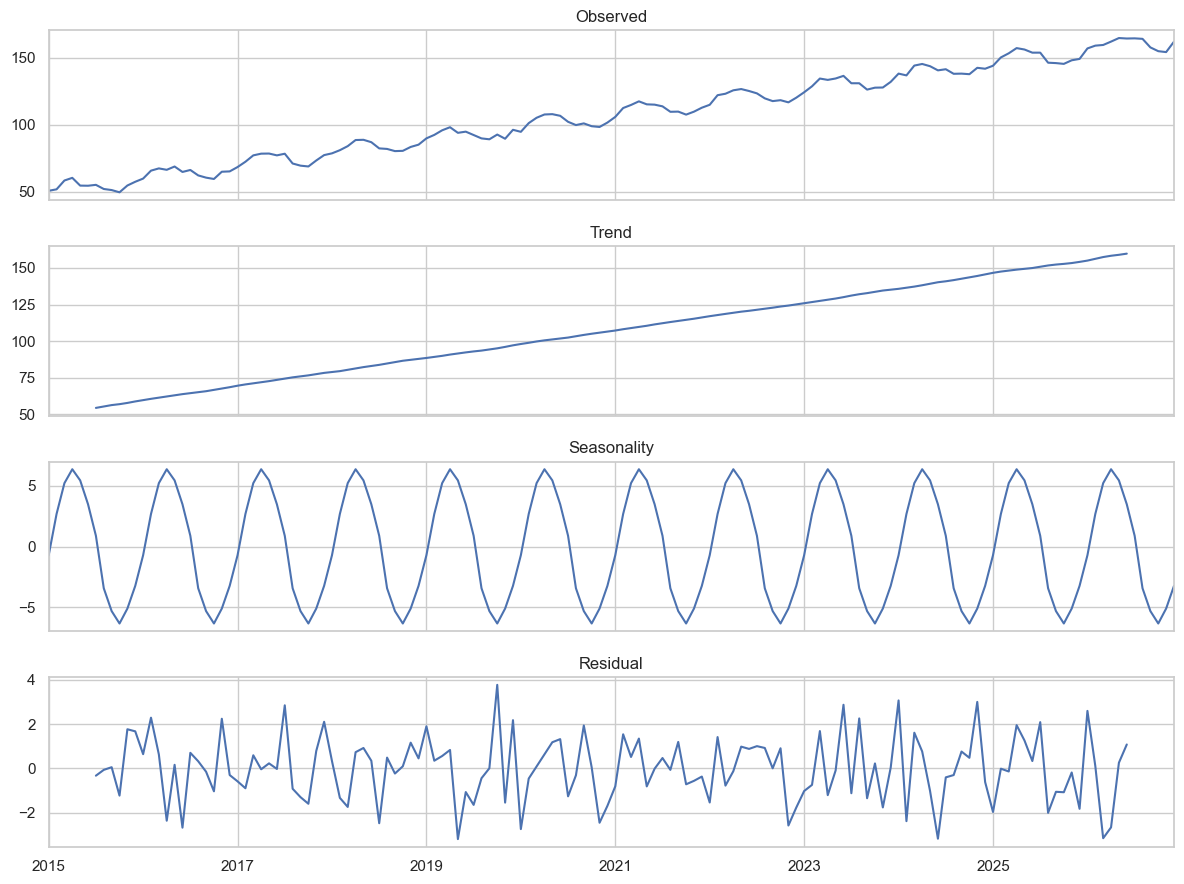

In [4]:
decomposition = seasonal_decompose(series, model="additive", period=12)

fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
decomposition.observed.plot(ax=axes[0], title="Observed")
decomposition.trend.plot(ax=axes[1], title="Trend")
decomposition.seasonal.plot(ax=axes[2], title="Seasonality")
decomposition.resid.plot(ax=axes[3], title="Residual")
plt.tight_layout()
plt.show()

## 5. Stationarity check

In [5]:
def adf_report(x, name):
    result = adfuller(x.dropna(), autolag="AIC")
    print(f"{name}: ADF statistic={result[0]:.3f}, p-value={result[1]:.4f}")
    print("Critical values:", {k: round(v, 3) for k, v in result[4].items()})

adf_report(series, "Raw series")
adf_report(series.diff(), "First difference")

Raw series: ADF statistic=0.150, p-value=0.9693
Critical values: {'1%': -3.482, '5%': -2.884, '10%': -2.579}
First difference: ADF statistic=-8.210, p-value=0.0000
Critical values: {'1%': -3.482, '5%': -2.884, '10%': -2.579}


## 6. Autocorrelation

ACF and PACF plots help choose AR and MA orders. The seasonal spikes at lags 12, 24, ... confirm the
yearly pattern.

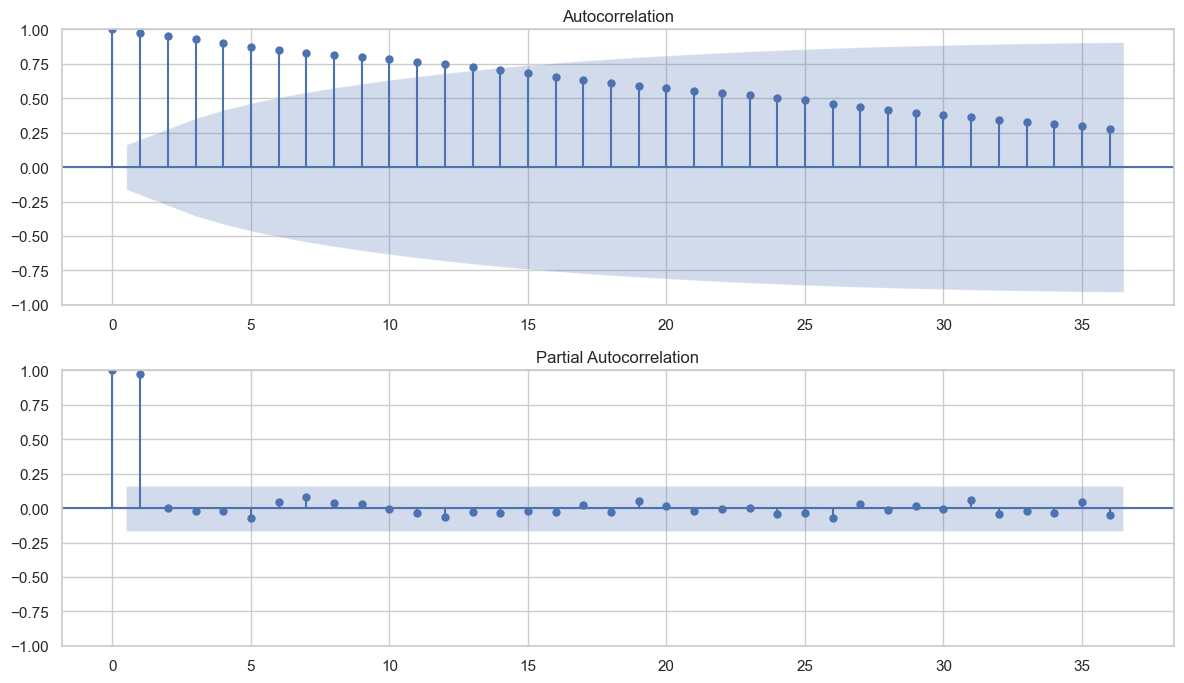

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
plot_acf(series, lags=36, ax=axes[0])
plot_pacf(series, lags=36, ax=axes[1], method="ywm")
plt.tight_layout()
plt.show()

## 7. Baselines: naive forecast and moving average

A forecast is only useful if it beats simple baselines.

In [7]:
test_size = 24
train = series.iloc[:-test_size]
test = series.iloc[-test_size:]

naive_forecast = pd.Series(train.iloc[-1], index=test.index)
moving_average_forecast = pd.Series(train.iloc[-12:].mean(), index=test.index)

def rmse(actual, predicted):
    return np.sqrt(mean_squared_error(actual, predicted))

baseline_rows = [
    {"model": "Naive (last value)", "MAE": mean_absolute_error(test, naive_forecast), "RMSE": rmse(test, naive_forecast)},
    {"model": "12-month mean", "MAE": mean_absolute_error(test, moving_average_forecast), "RMSE": rmse(test, moving_average_forecast)},
]
pd.DataFrame(baseline_rows).round(3)

,model,MAE,RMSE
0,Naive (last value),13.514,14.955
1,12-month mean,14.617,15.959


## 8. Regression with lag features

We create lag columns and train a linear model on the training portion. For a fair forecast we use
only lags that are available at prediction time.

### Why random splits leak

With a random split, the model can learn from future months and evaluate on past months. That is not
a forecast; it is interpolation.

In [8]:
def make_lag_features(values, n_lags=12):
    frame = pd.DataFrame({"y": values})
    for lag in range(1, n_lags + 1):
        frame[f"lag_{lag}"] = frame["y"].shift(lag)
    return frame.dropna()

lag_frame = make_lag_features(series, n_lags=12)
lag_frame.head()

,y,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,lag_10,lag_11,lag_12
2016-01-01,59.732061,57.355584,54.562644,49.493912,51.170245,51.967515,55.055681,54.395641,54.494082,60.281129,58.297055,51.720032,50.609434
2016-02-01,65.654482,59.732061,57.355584,54.562644,49.493912,51.170245,51.967515,55.055681,54.395641,54.494082,60.281129,58.297055,51.720032
2016-03-01,67.331171,65.654482,59.732061,57.355584,54.562644,49.493912,51.170245,51.967515,55.055681,54.395641,54.494082,60.281129,58.297055
2016-04-01,66.281415,67.331171,65.654482,59.732061,57.355584,54.562644,49.493912,51.170245,51.967515,55.055681,54.395641,54.494082,60.281129
2016-05-01,68.733654,66.281415,67.331171,65.654482,59.732061,57.355584,54.562644,49.493912,51.170245,51.967515,55.055681,54.395641,54.494082


In [9]:
split_index = len(lag_frame) - test_size

train_lags = lag_frame.iloc[:split_index]
test_lags = lag_frame.iloc[split_index:]

feature_cols = [c for c in lag_frame.columns if c.startswith("lag_")]
lag_model = LinearRegression()
lag_model.fit(train_lags[feature_cols], train_lags["y"])
lag_forecast = lag_model.predict(test_lags[feature_cols])

print("Lag regression MAE:", round(mean_absolute_error(test_lags["y"], lag_forecast), 3))
print("Lag regression RMSE:", round(rmse(test_lags["y"], lag_forecast), 3))

Lag regression MAE: 2.328
Lag regression RMSE: 2.777


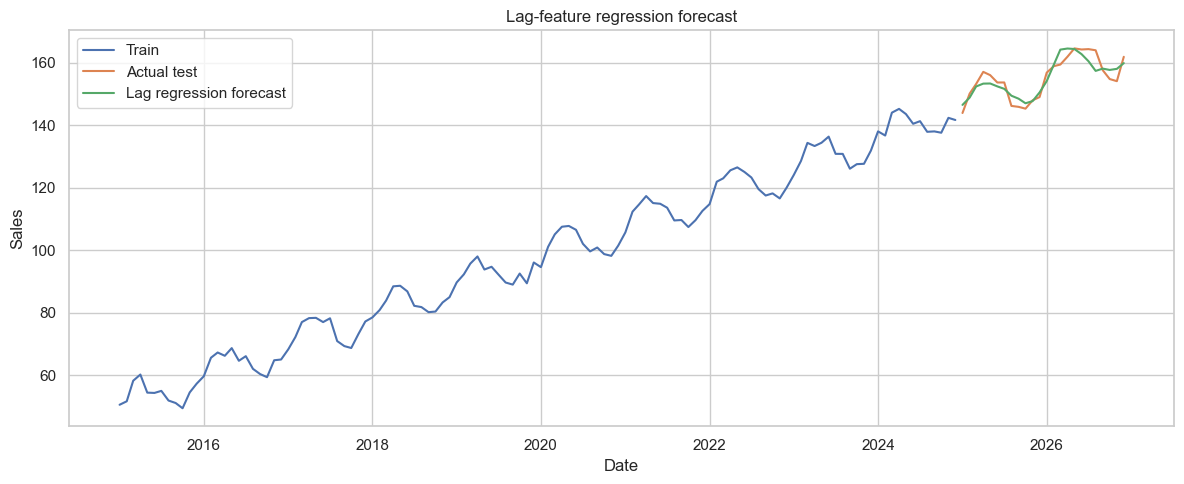

In [10]:
plt.figure(figsize=(12, 5))
plt.plot(train.index, train.values, label="Train")
plt.plot(test.index, test.values, label="Actual test")
plt.plot(test.index, lag_forecast, label="Lag regression forecast")
plt.title("Lag-feature regression forecast")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Walk-forward validation with `TimeSeriesSplit`

Instead of one split, we evaluate the model on several consecutive test blocks. This gives a more
stable estimate and mirrors how a forecast would be used in production.

In [11]:
tscv = TimeSeriesSplit(n_splits=4)
scores = []

for fold, (train_idx, test_idx) in enumerate(tscv.split(lag_frame), start=1):
    train_fold = lag_frame.iloc[train_idx]
    test_fold = lag_frame.iloc[test_idx]
    model = LinearRegression()
    model.fit(train_fold[feature_cols], train_fold["y"])
    predictions = model.predict(test_fold[feature_cols])
    scores.append({
        "fold": fold,
        "train_size": len(train_fold),
        "test_size": len(test_fold),
        "rmse": rmse(test_fold["y"], predictions),
    })

pd.DataFrame(scores).round(3)

,fold,train_size,test_size,rmse
0,1,28,26,2.266
1,2,54,26,1.328
2,3,80,26,1.867
3,4,106,26,2.802


## 10. ARIMA

We fit ARIMA on the training series and forecast the test horizon. A seasonal model such as
SARIMA would usually be better when seasonality is strong; ARIMA is shown here as a foundation.

In [12]:
arima_model = ARIMA(train, order=(1, 1, 1)).fit()
arima_forecast = arima_model.forecast(steps=test_size)

print(arima_model.summary().tables[1])
print("ARIMA MAE:", round(mean_absolute_error(test, arima_forecast), 3))
print("ARIMA RMSE:", round(rmse(test, arima_forecast), 3))

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5420      0.274      1.979      0.048       0.005       1.079
ma.L1         -0.2947      0.322     -0.916      0.360      -0.925       0.336
sigma2         9.5423      1.351      7.063      0.000       6.894      12.190
ARIMA MAE: 13.176
ARIMA RMSE: 14.642


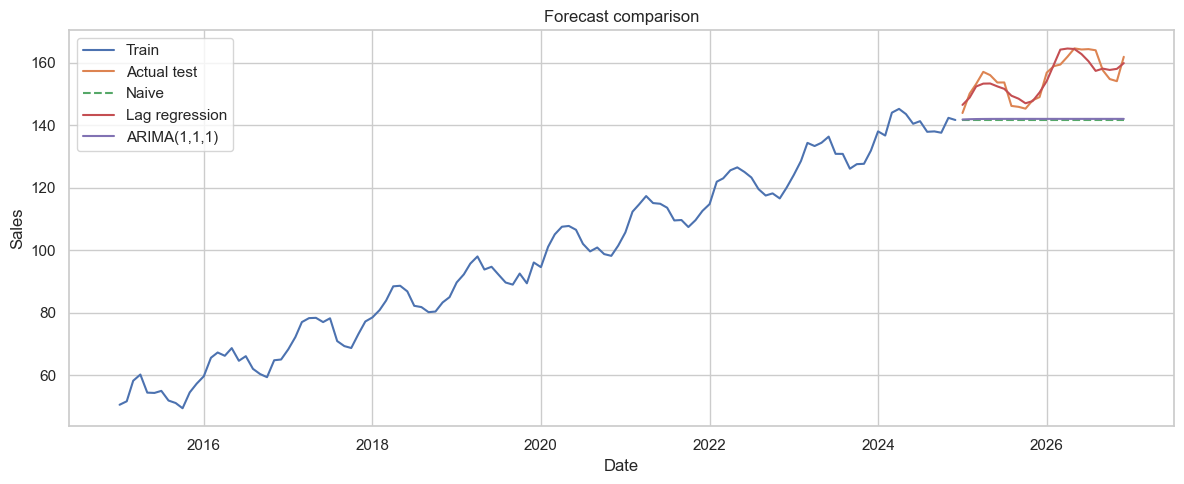

In [13]:
plt.figure(figsize=(12, 5))
plt.plot(train.index, train.values, label="Train")
plt.plot(test.index, test.values, label="Actual test")
plt.plot(test.index, naive_forecast, "--", label="Naive")
plt.plot(test.index, lag_forecast, label="Lag regression")
plt.plot(test.index, arima_forecast, label="ARIMA(1,1,1)")
plt.title("Forecast comparison")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()

## 11. Practical checklist

- Plot the series before modelling.
- Use a chronological split and walk-forward validation.
- Establish a naive baseline.
- Check stationarity and consider differencing.
- Account for seasonality (seasonal decomposition, SARIMA, seasonal lags).
- Keep the forecast horizon short when uncertainty matters; report prediction intervals.
- Monitor performance after deployment because patterns drift.

## Key takeaways

- Time order is information; random splits destroy it.
- Decomposition and ADF guide preprocessing choices.
- Lag features turn forecasting into supervised learning.
- ARIMA is a strong classical baseline; seasonal and external-regressor models extend it.
- Always compare with a naive forecast.

## Exercises

1. Create a multiplicative series and use `seasonal_decompose(model="multiplicative")`.
2. Add a 12-month seasonal lag and compare the regression RMSE.
3. Fit `SARIMAX` with a seasonal order of `(1, 1, 1, 12)`.
4. Use `TimeSeriesSplit` with more folds and plot the RMSE distribution.
5. Forecast a real dataset from your domain and compare naive, regression, and ARIMA baselines.